# M5 Retail Demand Forecasting — Notebook 1: Exploratory Data Analysis

**Project:** Retail demand forecasting and inventory decision support on the M5 (Walmart) dataset.
**This notebook:** understand the data, check its quality, and turn what we learn into modelling decisions.

| | |
|---|---|
| **Inputs** | `calendar.csv`, `sell_prices.csv`, `sales_train_evaluation.csv` (Kaggle: *M5 Forecasting – Accuracy*) |
| **Outputs** | `m5_sample_long.parquet` (clean long table), `m5_series_stats.parquet`, `subset_config.json` |
| **Libraries** | pandas, numpy, matplotlib, pyarrow |

**Scope.** The full M5 data has 30,490 item-store series. We work with a stratified sample of about 1,000 series from the four California stores (CA_1 to CA_4) and use only days `d_1` to `d_1913`. The last 28 days (`d_1914` to `d_1941`) are reserved as a final holdout and are never loaded here.

**Approach.** Each section asks one question of the data and ends with a modelling decision. The decisions are collected in the findings table in Section 11. Numbers quoted in the text come from our run (seed 42); re-running should reproduce them.

---
## 0. Setup and configuration

All settings are kept in one cell so the analysis is reproducible.

- `SEED` fixes the random sample.
- `LAST_TRAIN_DAY = 1913`: M5 has 1,941 days and the last 28 form the final holdout. We read only `d_1` to `d_1913`, so nothing in the EDA can be influenced by the holdout period.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- Config ----------
_ROOT = Path("..") if (not Path("data").exists() and Path("../data").exists()) else Path(".")   # works from the project root or from a notebooks/ sub-folder
RAW  = Path("/kaggle/input/competitions/m5-forecasting-accuracy")
PROC = Path("/kaggle/working/")
PROC.mkdir(parents=True, exist_ok=True)

STATE          = "CA"     # California: stores CA_1 .. CA_4
N_SERIES       = 1000     # number of item-store series to sample
SEED           = 42
LAST_TRAIN_DAY = 1913     # days after this one (final holdout) are never loaded

# ---------- Display settings ----------
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ---------- Check that the input files exist ----------
sales_path = RAW / "sales_train_evaluation.csv"
if not sales_path.exists():
    sales_path = RAW / "sales_train_validation.csv"
for p in [sales_path, RAW / "calendar.csv", RAW / "sell_prices.csv"]:
    print(f"{p}  ->  {'OK' if p.exists() else 'MISSING'}  ({p.stat().st_size/1e6:.1f} MB)" if p.exists() else f"{p}  ->  MISSING")

/kaggle/input/competitions/m5-forecasting-accuracy/sales_train_evaluation.csv  ->  OK  (121.7 MB)
/kaggle/input/competitions/m5-forecasting-accuracy/calendar.csv  ->  OK  (0.1 MB)
/kaggle/input/competitions/m5-forecasting-accuracy/sell_prices.csv  ->  OK  (203.4 MB)


---
## 1. Loading the data and understanding its structure

Before any analysis we need to know what one row represents (the *granularity*), because joins and aggregations depend on it.

| File | One row is | Shape |
|---|---|---|
| `sales_*.csv` | one item in one store (whole history in one row) | **wide**: one column per day (`d_1`, `d_2`, ...) |
| `calendar.csv` | one day | maps `d_*` to a date, weekday, events and SNAP flags |
| `sell_prices.csv` | one item, one store, one **week** | prices are weekly, not daily |

Memory: the day columns are read as `int16` (4x smaller than the default `int64`), and `usecols` restricts the file to `d_1`…`d_1913`.

In [2]:
# ---- Sales (wide format) ----
d_cols  = [f"d_{i}" for i in range(1, LAST_TRAIN_DAY + 1)]
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

sales = pd.read_csv(
    sales_path,
    usecols=id_cols + d_cols,
    dtype={c: "int16" for c in d_cols},
)
print("sales (wide) shape:", sales.shape)
print(f"memory: {sales.memory_usage(deep=True).sum()/1e6:.0f} MB")
sales.iloc[:5, :10]

sales (wide) shape: (30490, 1919)
memory: 128 MB


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


**Reading the table.** The sales table has 6 identifier columns plus one column per day, so a date is a *column name*, not a value. To analyse time we must convert it to long format (one row per series per day). This is done in Section 3.

In [3]:
# ---- Calendar ----
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
print("calendar shape:", calendar.shape)
print("date range:", calendar["date"].min().date(), "->", calendar["date"].max().date())
display(calendar.head(8))

# ---- Prices ----
prices = pd.read_csv(RAW / "sell_prices.csv")
print("\nprices shape:", prices.shape)
display(prices.head())

calendar shape: (1969, 14)
date range: 2011-01-29 -> 2016-06-19


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1
5,2011-02-03,11101,Thursday,6,2,2011,d_6,NaN,NaN,NaN,NaN,1,1,1
6,2011-02-04,11101,Friday,7,2,2011,d_7,NaN,NaN,NaN,NaN,1,0,0
7,2011-02-05,11102,Saturday,1,2,2011,d_8,NaN,NaN,NaN,NaN,1,1,1



prices shape: (6841121, 4)


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.580
1,CA_1,HOBBIES_1_001,11326,9.580
2,CA_1,HOBBIES_1_001,11327,8.260
3,CA_1,HOBBIES_1_001,11328,8.260
4,CA_1,HOBBIES_1_001,11329,8.260


**Observations on `calendar` and `sell_prices`**
- `d` in the calendar is the same key as the `d_*` columns in the sales table, so it is the join key.
- `wm_yr_wk` is a week identifier; it links daily sales to weekly prices.
- `event_name_1` and `event_type_1` are mostly missing. This is not an error: a missing value means "no event on that day".
- `snap_CA/TX/WI` flag days on which SNAP (a US food-assistance programme) benefits can be used in that state, which can affect food sales.

---
## 2. Sampling a subset (stratified)

The full data is about 58 million rows in long format, which is heavy for a laptop. We build a smaller subset first and scale later.

A plain random sample would contain mostly low-volume series, so we **stratify by volume**:
1. keep only California series,
2. compute each series' average daily sales,
3. split the series into three equal-sized tiers (low / mid / high volume),
4. draw the same number of series from each tier.

The tiers are computed on the training period only (`d_1`…`d_1913`).

In [4]:
sales = sales[sales["state_id"] == STATE].copy()
print(f"Total series in {STATE}: {len(sales)}")

# Average daily sales per series and its volume tier
sales["avg_sales"] = sales[d_cols].mean(axis=1)
sales["vol_tier"] = pd.qcut(
    sales["avg_sales"].rank(method="first"), q=3, labels=["low", "mid", "high"]
)

# Draw the same number of series from each tier
per_tier = N_SERIES // 3
parts = []
for tier in ["low", "mid", "high"]:
    grp = sales[sales["vol_tier"] == tier]
    parts.append(grp.sample(n=min(per_tier, len(grp)), random_state=SEED))
sales = pd.concat(parts).reset_index(drop=True)
sales["vol_tier"] = sales["vol_tier"].astype(str)

print(f"Series in sample: {len(sales)}")
print(sales["vol_tier"].value_counts().to_string())
print("\nStores:", sorted(sales["store_id"].unique()))
print("Categories:", sorted(sales["cat_id"].unique()))
sales[["id", "store_id", "cat_id", "vol_tier", "avg_sales"]].head()

Total series in CA: 12196
Series in sample: 999
vol_tier
low     333
mid     333
high    333

Stores: ['CA_1', 'CA_2', 'CA_3', 'CA_4']
Categories: ['FOODS', 'HOBBIES', 'HOUSEHOLD']


,id,store_id,cat_id,vol_tier,avg_sales
0,HOUSEHOLD_2_130_CA_3_evaluation,CA_3,HOUSEHOLD,low,0.095
1,HOUSEHOLD_2_230_CA_3_evaluation,CA_3,HOUSEHOLD,low,0.065
2,FOODS_3_633_CA_2_evaluation,CA_2,FOODS,low,0.041
3,FOODS_2_077_CA_2_evaluation,CA_2,FOODS,low,0.044
4,HOUSEHOLD_1_274_CA_3_evaluation,CA_3,HOUSEHOLD,low,0.152


---
## 3. Wide to long format and joins

For time-series analysis and ML features we need **one row per series per day**.

1. `melt` turns the day columns into rows (about 1,000 x 1,913 = 1.9 million rows).
2. Join with `calendar` on `d` to get the date, weekday, events and SNAP flag.
3. Join with `sell_prices` on `(store_id, item_id, wm_yr_wk)`.

**Check after every join.** A left join must not change the number of rows: more rows means duplicate keys in the right table, fewer means lost data. We enforce this with `assert`, so a faulty join stops the notebook instead of silently corrupting the data.

In [5]:
# ---- 1) Wide -> Long ----
long = sales.melt(
    id_vars=id_cols + ["vol_tier"],
    value_vars=d_cols,
    var_name="d",
    value_name="sales",
)
n_before = len(long)
print("Long rows:", f"{n_before:,}", " (expected:", f"{len(sales) * len(d_cols):,})")

# ---- 2) Calendar join ----
snap_col = f"snap_{STATE}"
cal_small = calendar[["d", "date", "wm_yr_wk", "weekday", "wday", "month", "year",
                      "event_name_1", "event_type_1", snap_col]].rename(columns={snap_col: "snap"})
long = long.merge(cal_small, on="d", how="left")
assert len(long) == n_before, "Calendar join changed the number of rows!"
assert long["date"].notna().all(), "Some days did not match the calendar!"

# ---- 3) Price join ----
price_keys = ["store_id", "item_id", "wm_yr_wk"]
prices_s = prices[prices["store_id"].isin(sales["store_id"].unique()) &
                  prices["item_id"].isin(sales["item_id"].unique())]
long = long.merge(prices_s, on=price_keys, how="left")
assert len(long) == n_before, "Price join added rows (duplicate keys?)!"

print("Rows after joins:", f"{len(long):,}", "  (must be unchanged)")
print(f"Price match rate: {long['sell_price'].notna().mean():.1%}  (share of rows with a price)")

# Sort by series and date (required for lag features)
long = long.sort_values(["id", "date"]).reset_index(drop=True)
long = long.drop(columns=["d"])
print(f"\nMemory: {long.memory_usage(deep=True).sum()/1e6:.0f} MB")
long.head()

Long rows: 1,911,087  (expected: 1,911,087)
Rows after joins: 1,911,087   (must be unchanged)
Price match rate: 78.3%  (share of rows with a price)

Memory: 1131 MB


,id,item_id,dept_id,cat_id,store_id,state_id,vol_tier,sales,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,snap,sell_price
0,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,CA,low,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0,NaN
1,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,CA,low,0,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,0,NaN
2,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,CA,low,0,2011-01-31,11101,Monday,3,1,2011,NaN,NaN,0,NaN
3,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,CA,low,0,2011-02-01,11101,Tuesday,4,2,2011,NaN,NaN,1,NaN
4,FOODS_1_008_CA_4_evaluation,FOODS_1_008,FOODS_1,FOODS,CA_4,CA,low,0,2011-02-02,11101,Wednesday,5,2,2011,NaN,NaN,1,NaN


**Price match rate.** Only 78.3% of the rows have a price after the join. This is explained in Section 5: a missing price means the item was not yet on sale in that store.

---
## 4. Data-quality checks

Poor data quality is a common cause of poor models, so these five checks are run on every new dataset:

| Check | Question | If it fails |
|---|---|---|
| Duplicates | Is any (series, date) pair repeated? | double counting |
| Missing values | Where and why are values missing? | decide: error or meaningful |
| Ranges | Negative sales? Zero or negative prices? | bug or bad data |
| Date continuity | Does every series have every day? | lag/rolling features break |
| Join rate | How many rows matched? | silent data loss |

In [6]:
print("1) Duplicates (id + date):", long.duplicated(["id", "date"]).sum())

print("\n2) Missing values per column:")
miss = long.isna().sum()
print(miss[miss > 0].to_string())

print("\n3) Range checks:")
print("   min sales :", long["sales"].min(), " (must be non-negative)")
print("   max sales :", long["sales"].max())
print("   min price :", long["sell_price"].min())
print("   max price :", long["sell_price"].max())

print("\n4) Date continuity:")
days_per_series = long.groupby("id").size()
print("   days per series (unique values):", days_per_series.unique())
all_dates = pd.Series(sorted(long["date"].unique()))
print("   date gaps (difference > 1 day):", (all_dates.diff().dropna() > pd.Timedelta(days=1)).sum())
print("   date range:", all_dates.min().date(), "->", all_dates.max().date())

1) Duplicates (id + date): 0

2) Missing values per column:
event_name_1    1757241
event_type_1    1757241
sell_price       415030

3) Range checks:
   min sales : 0  (must be non-negative)
   max sales : 294
   min price : 0.2
   max price : 30.98

4) Date continuity:
   days per series (unique values): [1913]
   date gaps (difference > 1 day): 0
   date range: 2011-01-29 -> 2016-04-24


**Results.** There are no duplicate keys, no negative sales, and every series has exactly 1,913 consecutive days with no gaps. Missing `event_*` values are expected (no event). Missing `sell_price` values are examined next.

---
## 5. Structural zeros (an important M5 property)

**Observation.** `sell_price` is missing for 21.7% of rows (415,030 of 1,911,087).

**Hypothesis.** If an item has no price in a week, it was not sold in that store that week (not launched yet). Then `sales = 0` in that period does not mean "no demand"; it means "the item did not exist". We call these *structural zeros*.

**Why it matters.** If a model learns these zeros as real demand it will under-estimate demand for new items, and metrics will look better than they should because zeros are easy to predict.

**Test.** Under the hypothesis there should be no positive sales in rows without a price. **Fix.** For each series find the date of the first price and mark earlier rows `is_available = False`.

In [7]:
# ---- Hypothesis test ----
no_price = long["sell_price"].isna()
print("Rows with missing price:", f"{no_price.sum():,}  ({no_price.mean():.1%})")
print("Rows without a price but with sales > 0:", f"{(long.loc[no_price, 'sales'] > 0).sum():,}")
print("Rows without a price and with sales == 0:", f"{(long.loc[no_price, 'sales'] == 0).sum():,}")

# ---- Availability flag ----
first_price_date = (long[long["sell_price"].notna()]
                    .groupby("id")["date"].min())
long["first_price_date"] = long["id"].map(first_price_date)
long["is_available"] = long["date"] >= long["first_price_date"]   # NaT => False

print("\nSeries that never had a price:", long.loc[long["first_price_date"].isna(), "id"].nunique())
print(f"Unavailable (structural) rows: {(~long['is_available']).mean():.1%}")

zero_all   = (long["sales"] == 0).mean()
zero_avail = (long.loc[long["is_available"], "sales"] == 0).mean()
print(f"\nZero-sales share, all rows             : {zero_all:.1%}")
print(f"Zero-sales share, available rows only  : {zero_avail:.1%}")

Rows with missing price: 415,030  (21.7%)
Rows without a price but with sales > 0: 0
Rows without a price and with sales == 0: 415,030

Series that never had a price: 0
Unavailable (structural) rows: 21.7%

Zero-sales share, all rows             : 65.8%
Zero-sales share, available rows only  : 56.4%


**Result.** None of the 415,030 rows without a price has positive sales, so the hypothesis is supported. The zero-sales share is 65.8% over all rows but 56.4% once only available rows are considered; the difference is the effect of structural zeros.

**Decision.** Training and evaluation use only `is_available == True` rows. Unavailable rows are treated as missing (`NaN`), not as zero, when features are built.

From here on `avail` denotes the available rows only.

In [8]:
avail = long[long["is_available"]].copy()
print(f"Available rows: {len(avail):,} / {len(long):,}  ({len(avail)/len(long):.1%})")

Available rows: 1,496,057 / 1,911,087  (78.3%)


---
## 6. The target variable (sales)

The loss function and the metrics must match the nature of the target, so we study its distribution first.

### 6.1 Distribution of daily sales

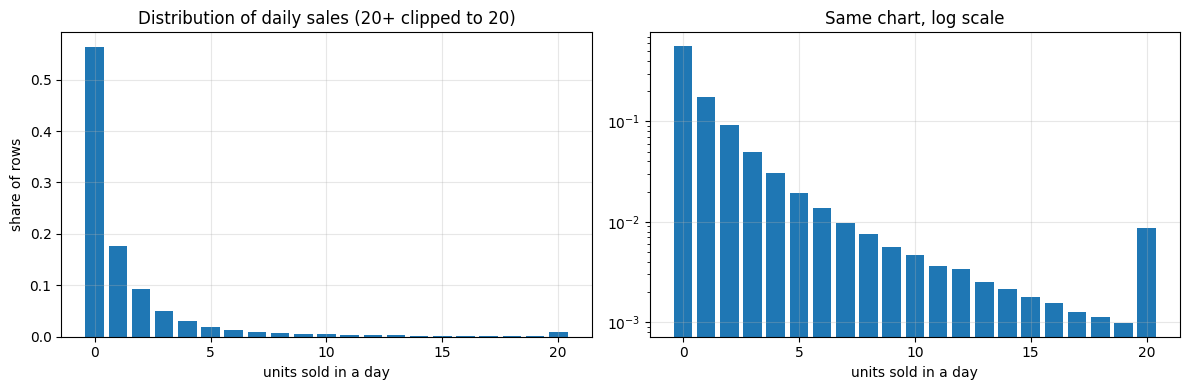

count   1,496,057.000
mean            1.552
std             3.803
min             0.000
25%             0.000
50%             0.000
75%             2.000
max           294.000

Median = 0.0, Mean = 1.55  (mean > median => right-skewed)


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

vc = avail["sales"].clip(upper=20).value_counts().sort_index()
ax[0].bar(vc.index, vc.values / len(avail))
ax[0].set_title("Distribution of daily sales (20+ clipped to 20)")
ax[0].set_xlabel("units sold in a day"); ax[0].set_ylabel("share of rows")

# log scale makes the tail visible
ax[1].bar(vc.index, vc.values / len(avail))
ax[1].set_yscale("log")
ax[1].set_title("Same chart, log scale")
ax[1].set_xlabel("units sold in a day")
plt.tight_layout(); plt.show()

print(avail["sales"].describe().to_string())
print(f"\nMedian = {avail['sales'].median()}, Mean = {avail['sales'].mean():.2f}  (mean > median => right-skewed)")

**Observations.**
- Daily sales are small non-negative integers with a very large mass at zero: the median is 0 and the mean is 1.55 (right-skewed count data).

**Decision.** Squared-error loss is a poor fit for this kind of target. A Tweedie (or Poisson) objective is more appropriate.

### 6.2 Series-level statistics and demand classification

Forecasting literature distinguishes four demand patterns using two numbers (Syntetos-Boylan):
- **ADI** (average demand interval): average number of days between non-zero sales.
- **CV²**: squared coefficient of variation of the non-zero sales quantities.

| | CV² < 0.49 | CV² >= 0.49 |
|---|---|---|
| **ADI < 1.32** | smooth | erratic |
| **ADI >= 1.32** | intermittent | lumpy |

In [10]:
# ---- Series-level statistics (available days only) ----
g = avail.groupby("id")["sales"]
stats = pd.DataFrame({
    "n_days": g.size(),
    "mean":   g.mean(),
    "std":    g.std(),
})
stats["zero_share"] = (avail.assign(z=avail["sales"] == 0).groupby("id")["z"].mean())
stats["cv"] = stats["std"] / stats["mean"].replace(0, np.nan)

# ---- ADI and CV^2 (non-zero days) ----
nz = avail[avail["sales"] > 0].groupby("id")["sales"]
stats["nz_count"] = nz.size()
stats["nz_count"] = stats["nz_count"].fillna(0)
stats["adi"] = stats["n_days"] / stats["nz_count"].replace(0, np.nan)
stats["cv2"] = ((nz.std() / nz.mean()) ** 2).reindex(stats.index).fillna(0)

# ---- Classification ----
conds = [
    stats["adi"].isna(),
    (stats["adi"] < 1.32) & (stats["cv2"] < 0.49),
    (stats["adi"] < 1.32) & (stats["cv2"] >= 0.49),
    (stats["adi"] >= 1.32) & (stats["cv2"] < 0.49),
    (stats["adi"] >= 1.32) & (stats["cv2"] >= 0.49),
]
labels = ["no_sales", "smooth", "erratic", "intermittent", "lumpy"]
stats["demand_class"] = np.select(conds, labels, default="unknown")

# add the series metadata
meta = sales.set_index("id")[["item_id", "store_id", "cat_id", "dept_id", "vol_tier"]]
stats = stats.join(meta)

print("Demand class counts:")
print(stats["demand_class"].value_counts().to_string())
print("\nVolume tier x demand class:")
print(pd.crosstab(stats["vol_tier"], stats["demand_class"]))
stats.sort_values("mean", ascending=False).head(5)

Demand class counts:
demand_class
intermittent    708
lumpy           196
smooth           61
erratic          34

Volume tier x demand class:
demand_class  erratic  intermittent  lumpy  smooth
vol_tier                                          
high               34           141     98      60
low                 0           300     33       0
mid                 0           267     65       1


,n_days,mean,std,zero_share,cv,nz_count,adi,cv2,demand_class,item_id,store_id,cat_id,dept_id,vol_tier
id,,,,,,,,,,,,,,
FOODS_2_197_CA_1_evaluation,1913,21.274,12.736,0.083,0.599,1754,1.091,0.245,smooth,FOODS_2_197,CA_1,FOODS,FOODS_2,high
FOODS_3_501_CA_3_evaluation,1913,20.774,15.266,0.133,0.735,1659,1.153,0.336,smooth,FOODS_3_501,CA_3,FOODS,FOODS_3,high
FOODS_2_276_CA_3_evaluation,1913,20.514,16.713,0.068,0.815,1782,1.074,0.550,erratic,FOODS_2_276,CA_3,FOODS,FOODS_2,high
HOUSEHOLD_1_339_CA_3_evaluation,1388,19.468,14.921,0.070,0.766,1291,1.075,0.477,smooth,HOUSEHOLD_1_339,CA_3,HOUSEHOLD,HOUSEHOLD_1,high
FOODS_3_741_CA_1_evaluation,1913,18.479,13.711,0.065,0.742,1789,1.069,0.450,smooth,FOODS_3_741,CA_1,FOODS,FOODS_3,high


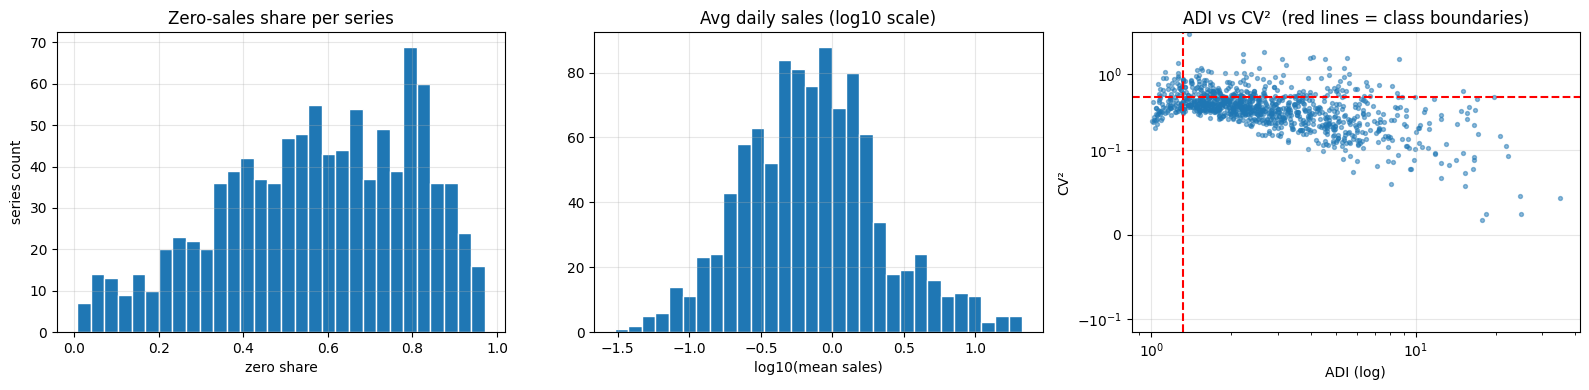

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# (a) zero share histogram
ax[0].hist(stats["zero_share"], bins=30, edgecolor="white")
ax[0].set_title("Zero-sales share per series")
ax[0].set_xlabel("zero share"); ax[0].set_ylabel("series count")

# (b) mean sales histogram (log)
ax[1].hist(np.log10(stats["mean"].clip(lower=1e-3)), bins=30, edgecolor="white")
ax[1].set_title("Avg daily sales (log10 scale)")
ax[1].set_xlabel("log10(mean sales)")

# (c) ADI vs CV2 scatter
plot_df = stats.dropna(subset=["adi"])
ax[2].scatter(plot_df["adi"], plot_df["cv2"], s=8, alpha=0.5)
ax[2].axvline(1.32, color="red", ls="--"); ax[2].axhline(0.49, color="red", ls="--")
ax[2].set_xscale("log"); ax[2].set_yscale("symlog", linthresh=0.1)
ax[2].set_title("ADI vs CV²  (red lines = class boundaries)")
ax[2].set_xlabel("ADI (log)"); ax[2].set_ylabel("CV²")
plt.tight_layout(); plt.show()

**Observations (our sample, 999 series).**
- 640 of 999 series have more than 50% zero-sales days.
- Demand classes: 708 intermittent, 196 lumpy, 61 smooth, 34 erratic. Most series are therefore sparse.

**Decisions.**
- Use a Tweedie objective and include intermittent-demand baselines (Croston/SBA).
- Avoid MAPE (undefined at zero actuals); use WAPE, MAE, MASE.
- Report errors by demand class and volume tier, not only overall.

---
## 7. Time patterns

We look for trend, weekly and yearly seasonality, events, and anomalies. Patterns found here become features.

### 7.1 Aggregate level

Aggregating over all series reduces noise, so patterns are easiest to see here. The red line is the 28-day moving average.

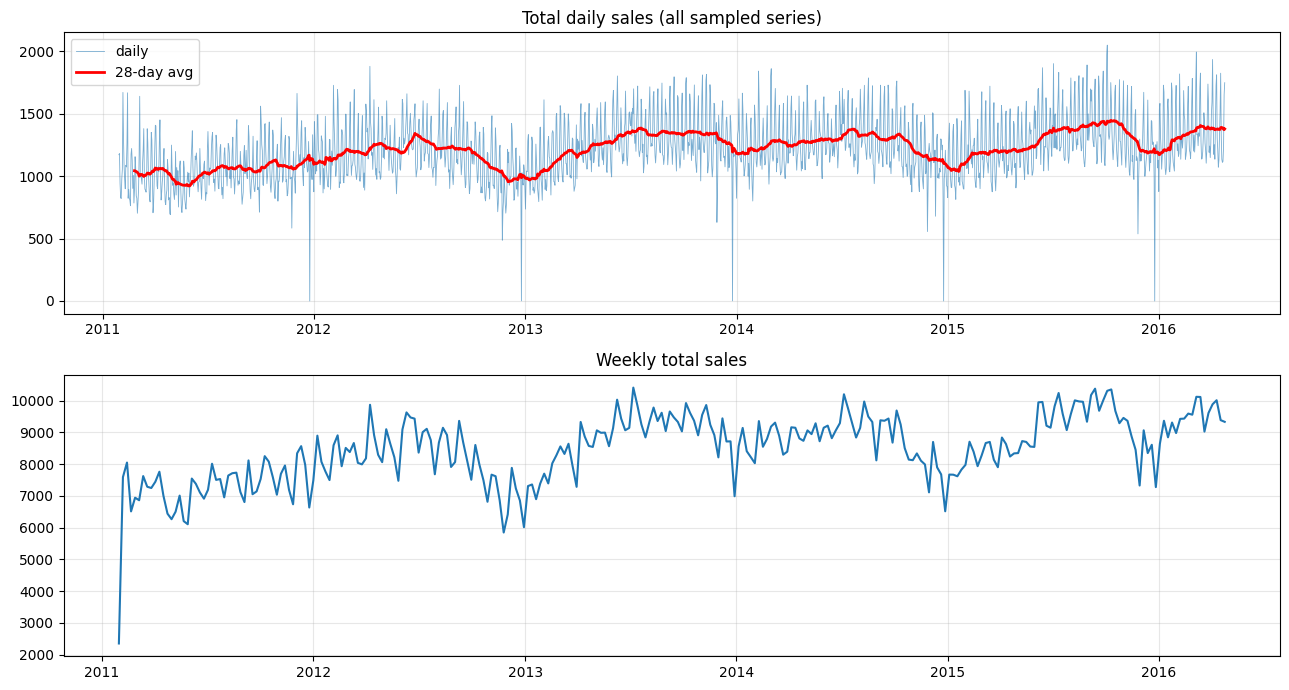

In [12]:
daily = long.groupby("date")["sales"].sum().rename("total").to_frame()
daily = daily.join(cal_small.set_index("date")[["weekday", "event_name_1", "event_type_1", "snap"]])

fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(daily.index, daily["total"], lw=0.6, alpha=0.6, label="daily")
ax[0].plot(daily.index, daily["total"].rolling(28).mean(), lw=2, color="red", label="28-day avg")
ax[0].set_title("Total daily sales (all sampled series)"); ax[0].legend()

weekly = daily["total"].resample("W").sum()
ax[1].plot(weekly.index, weekly.values)
ax[1].set_title("Weekly total sales")
plt.tight_layout(); plt.show()

Next we list the five days with the lowest total sales: extreme points are often data issues or special events.

In [13]:
print("Five days with the lowest total sales:")
display(daily.nsmallest(5, "total")[["total", "weekday", "event_name_1"]])

Five days with the lowest total sales:


,total,weekday,event_name_1
date,,,
2011-12-25,0,Sunday,Christmas
2014-12-25,0,Thursday,Christmas
2015-12-25,0,Friday,Christmas
2012-12-25,1,Tuesday,Christmas
2013-12-25,1,Wednesday,Christmas


**Observation.** The lowest-sales days are all 25 December (total sales of 0 or 1 in every year from 2011 to 2015). The stores are closed on Christmas Day.

**Decision.** Add an `is_christmas` flag so the model does not read this as a collapse in demand.

### 7.2 Weekly and yearly seasonality

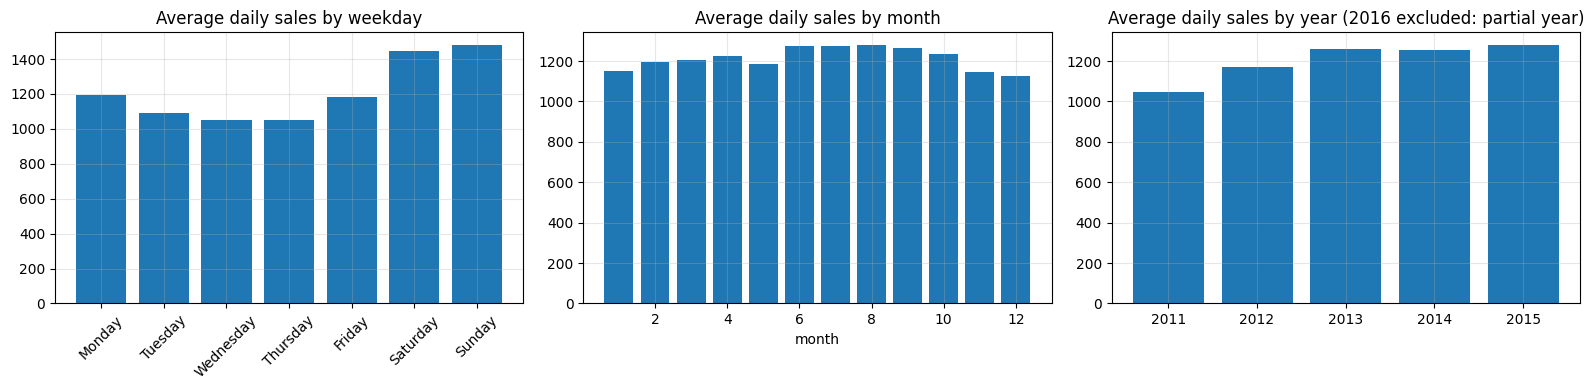

Weekday index (1.0 = average day):
weekday
Monday      0.983
Tuesday     0.897
Wednesday   0.866
Thursday    0.866
Friday      0.976
Saturday    1.193
Sunday      1.219


In [14]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = daily.groupby("weekday")["total"].mean().reindex(order)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(dow.index, dow.values); ax[0].tick_params(axis="x", rotation=45)
ax[0].set_title("Average daily sales by weekday")

month_avg = daily.groupby(daily.index.month)["total"].mean()
ax[1].bar(month_avg.index, month_avg.values)
ax[1].set_title("Average daily sales by month"); ax[1].set_xlabel("month")

year_avg = daily[daily.index.year < 2016].groupby(daily[daily.index.year < 2016].index.year)["total"].mean()
ax[2].bar(year_avg.index.astype(str), year_avg.values)
ax[2].set_title("Average daily sales by year (2016 excluded: partial year)")
plt.tight_layout(); plt.show()

print("Weekday index (1.0 = average day):")
print((dow / dow.mean()).round(3).to_string())

**Observations.**
- Weekday index (1.0 = average day): Monday 0.98, Tuesday 0.90, Wednesday 0.87, Thursday 0.87, Friday 0.98, Saturday 1.19, Sunday 1.22. Weekly seasonality is strong, with weekends about 20% above average.

**Decisions.** Add `dow`/`is_weekend` features and same-weekday lags (multiples of 7 days). Because the pattern is strong, lags should preserve the weekday.

### 7.3 Individual series

Aggregates hide how different single series are. We plot one series from each demand class (last 365 days).

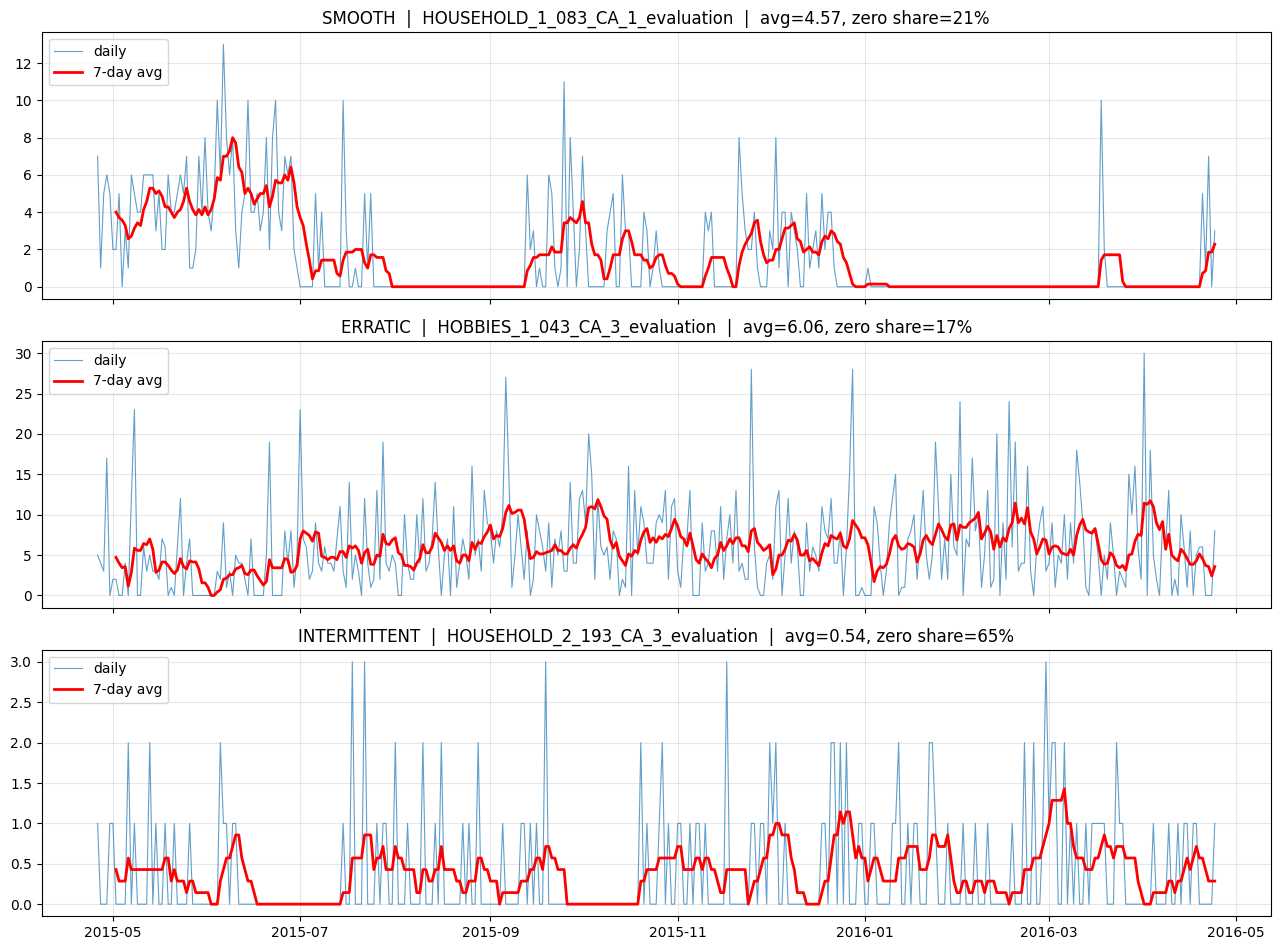

In [15]:
def pick_mid(cls):
    """Series of this class with median volume (neither the largest nor the smallest)."""
    s = stats[stats["demand_class"] == cls].sort_values("mean")
    return None if s.empty else s.index[len(s) // 2]

chosen = [(c, pick_mid(c)) for c in ["smooth", "erratic", "intermittent", "lumpy"]]
chosen = [(c, i) for c, i in chosen if i is not None][:3]

fig, axes = plt.subplots(len(chosen), 1, figsize=(13, 3.2 * len(chosen)), sharex=True)
axes = np.atleast_1d(axes)
for ax, (cls, sid) in zip(axes, chosen):
    s = avail[avail["id"] == sid].set_index("date")["sales"].iloc[-365:]
    ax.plot(s.index, s.values, lw=0.8, alpha=0.7, label="daily")
    ax.plot(s.index, s.rolling(7).mean(), lw=2, color="red", label="7-day avg")
    ax.set_title(f"{cls.upper()}  |  {sid}  |  avg={stats.loc[sid,'mean']:.2f}, zero share={stats.loc[sid,'zero_share']:.0%}")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Observation.** For intermittent and lumpy series the daily plot is mostly zeros with occasional spikes. A model trained with squared error will struggle on these, so performance is later reported by demand class.

---
## 8. Events and SNAP

Comparing event days to non-event days directly is unfair if events cluster on particular weekdays (*confounding*). We therefore compute a **weekday-adjusted index**: each day's total divided by the mean total for that weekday (1.0 = typical for that weekday) and compare indices.

In [16]:
# Weekday-adjusted index
daily["dow_mean"] = daily.groupby("weekday")["total"].transform("mean")
daily["idx"] = daily["total"] / daily["dow_mean"]
daily["has_event"] = daily["event_name_1"].notna()

print("Event vs non-event days (weekday-adjusted index):")
print(daily.groupby("has_event")["idx"].agg(["mean", "count"]).rename(index={False: "no event", True: "event"}).to_string())

print("\nBy event type:")
print(daily.assign(event_type_1=daily["event_type_1"].fillna("None"))
           .groupby("event_type_1")["idx"].agg(["mean", "count"]).sort_values("mean").to_string())

ev = (daily[daily["has_event"]].groupby("event_name_1")["idx"].agg(["mean", "count"]).sort_values("mean"))
print("\nSix events with the lowest index:")
print(ev.head(6).to_string())
print("\nSix events with the highest index:")
print(ev.tail(6).to_string())

Event vs non-event days (weekday-adjusted index):
           mean  count
has_event             
no event  1.006   1759
event     0.931    154

By event type:
              mean  count
event_type_1             
National     0.875     51
Cultural     0.887     35
Sporting     0.988     16
Religious    0.997     52
None         1.006   1759

Six events with the lowest index:
               mean  count
event_name_1              
Christmas     0.000      5
Thanksgiving  0.532      5
NewYear       0.716      5
Mother's day  0.820      5
Halloween     0.828      5
ValentinesDay 0.848      6

Six events with the highest index:
                mean  count
event_name_1               
ColumbusDay    1.051      5
MemorialDay    1.062      5
NBAFinalsStart 1.073      5
Ramadan starts 1.079      5
PresidentsDay  1.094      6
LaborDay       1.220      5


**Observation.** The mean index is 0.93 on event days and 1.01 on non-event days. Individual events differ in direction (for example Christmas pulls the average down), and each event occurs only about five times, so event-level conclusions are tentative.

**Decision.** Include event type and flag features, plus a separate Christmas flag.

### SNAP days

If SNAP affects food purchases we expect a larger lift in FOODS than in HOBBIES or HOUSEHOLD, which acts as a natural control.

In [17]:
cat_daily = (long.groupby(["date", "cat_id"])["sales"].sum().reset_index()
                 .merge(cal_small[["date", "weekday", "snap"]], on="date", how="left"))
cat_daily["idx"] = cat_daily["sales"] / cat_daily.groupby(["cat_id", "weekday"])["sales"].transform("mean")

snap_effect = cat_daily.groupby(["cat_id", "snap"])["idx"].mean().unstack()
snap_effect.columns = ["non-SNAP day", "SNAP day"]
snap_effect["SNAP lift %"] = (snap_effect["SNAP day"] / snap_effect["non-SNAP day"] - 1) * 100
print("SNAP day vs normal day (weekday-adjusted index):")
snap_effect

SNAP day vs normal day (weekday-adjusted index):


,non-SNAP day,SNAP day,SNAP lift %
cat_id,,,
FOODS,0.960,1.080,12.490
HOBBIES,0.987,1.027,4.114
HOUSEHOLD,0.988,1.025,3.778


**Observation.** Weekday-adjusted lift on SNAP days: FOODS +12.5%, HOBBIES +4.1%, HOUSEHOLD +3.8%. The effect is largest for food, as expected. The non-zero lift for the other categories suggests part of the effect may come from the timing of SNAP days (early in the month) rather than SNAP itself.

**Caution.** This is an observed association, not proof of causation. **Decision.** Keep the `snap` feature; tree models can learn the interaction with category.

---
## 9. Price and sales

Raw prices are not comparable across items, so we use **relative price** = price / the series' median price, and **relative sales** = sales / the series' average sales. Relative price is binned and the mean relative sales is computed per bin.

                       mean    count
price_bin                           
<0.85 (deep discount) 0.978    23961
0.85-0.95             1.144   106468
0.95-1.05 (normal)    0.997  1251453
1.05-1.15             0.928    94248
>1.15 (expensive)     0.807    19927


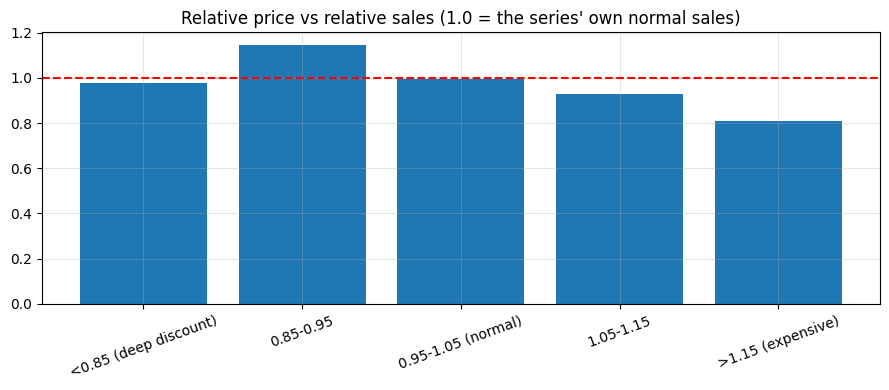


Weeks in which the price changed: 1.1%


In [18]:
p = avail[avail["sell_price"].notna()].copy()
p["price_ratio"] = p["sell_price"] / p.groupby("id")["sell_price"].transform("median")
series_mean = p.groupby("id")["sales"].transform("mean").replace(0, np.nan)
p["sales_norm"] = p["sales"] / series_mean
p = p.dropna(subset=["sales_norm"])

bins = [0, 0.85, 0.95, 1.05, 1.15, 10]
labels = ["<0.85 (deep discount)", "0.85-0.95", "0.95-1.05 (normal)", "1.05-1.15", ">1.15 (expensive)"]
p["price_bin"] = pd.cut(p["price_ratio"], bins=bins, labels=labels)

pb = p.groupby("price_bin", observed=True)["sales_norm"].agg(["mean", "count"])
print(pb.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pb.index.astype(str), pb["mean"])
ax.axhline(1.0, color="red", ls="--")
ax.set_title("Relative price vs relative sales (1.0 = the series' own normal sales)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# How often does the price change?
pw = prices_s.sort_values(["store_id", "item_id", "wm_yr_wk"]).copy()
pw["changed"] = pw.groupby(["store_id", "item_id"])["sell_price"].diff().fillna(0) != 0
print(f"\nWeeks in which the price changed: {pw['changed'].mean():.1%}")

**Observations.**
- Prices change in only 1.05% of store-item weeks, so price features can have limited influence overall.
- Mean relative sales by price bin: below 0.85: 0.98; 0.85-0.95: 1.14; 0.95-1.05 (normal): 1.00; 1.05-1.15: 0.93; above 1.15: 0.81. Sales are lowest at the highest relative prices and highest at moderate discounts. The deepest discounts do not show the highest sales, so the relationship is not monotonic and is probably confounded (for example by promotions or by which items receive deep discounts).

**Decision.** Create `sell_price`, `price_change_1w` and `price_vs_past_mean`, and measure their value with an ablation (Notebook 2) rather than assuming it.

---
## 10. Segment-wise comparison

A single overall average hides differences between segments. We compute the baseline level of difficulty per store, category and department so that later error analysis has a reference.

Average zero-sales share by category: FOODS 49%, HOUSEHOLD 61%, HOBBIES 69%. By store: CA_3 51%, CA_1 56%, CA_2 59%, CA_4 66%.

In [19]:
seg_store = stats.groupby("store_id").agg(series=("mean", "size"), avg_sales=("mean", "mean"), avg_zero_share=("zero_share", "mean"))
seg_cat   = stats.groupby("cat_id").agg(series=("mean", "size"), avg_sales=("mean", "mean"), avg_zero_share=("zero_share", "mean"))
seg_dept  = stats.groupby("dept_id").agg(series=("mean", "size"), avg_sales=("mean", "mean"), avg_zero_share=("zero_share", "mean"))

print("By store:");    display(seg_store)
print("By category:"); display(seg_cat)
print("By department:"); display(seg_dept)

print("\nDemand class share, category-wise:")
print(pd.crosstab(stats["cat_id"], stats["demand_class"], normalize="index").round(3))

By store:


,series,avg_sales,avg_zero_share
store_id,,,
CA_1,258,1.548,0.556
CA_2,245,1.064,0.589
CA_3,262,2.220,0.506
CA_4,234,0.820,0.655


By category:


,series,avg_sales,avg_zero_share
cat_id,,,
FOODS,451,1.941,0.493
HOBBIES,224,0.945,0.691
HOUSEHOLD,324,1.069,0.607


By department:


,series,avg_sales,avg_zero_share
dept_id,,,
FOODS_1,72,1.461,0.540
FOODS_2,132,1.732,0.529
FOODS_3,247,2.193,0.460
HOBBIES_1,162,1.209,0.633
HOBBIES_2,62,0.254,0.843
HOUSEHOLD_1,165,1.626,0.508
HOUSEHOLD_2,159,0.491,0.710



Demand class share, category-wise:
demand_class  erratic  intermittent  lumpy  smooth
cat_id                                            
FOODS           0.044         0.574  0.290   0.091
HOBBIES         0.040         0.768  0.192   0.000
HOUSEHOLD       0.015         0.855  0.068   0.062


**Observation.** HOBBIES and CA_4 are the sparsest segments, so they are expected to be the hardest to forecast. This is checked in the error analysis of Notebooks 2, 3 and 5.

---
## 11. Findings and modelling decisions

| # | Observation | Interpretation | Decision |
|---|---|---|---|
| 1 | 0 of 415,030 rows without a price have sales > 0; 21.7% of rows are unavailable | Missing price means the item was not on sale (structural zeros) | `is_available` flag; train/evaluate on available rows only; treat unavailable as NaN |
| 2 | 640 of 999 series have > 50% zero days; 708 intermittent, 196 lumpy | Sparse, count-like demand | Tweedie objective; Croston/SBA baseline; avoid MAPE |
| 3 | Weekday index 0.87 (Wed/Thu) to 1.22 (Sun) | Strong weekly seasonality | `dow`, `is_weekend`, same-weekday lags |
| 4 | Total sales 0-1 on every 25 December | Stores closed | `is_christmas` flag |
| 5 | SNAP lift FOODS +12.5% vs +4.1% / +3.8% | SNAP mainly affects food (association) | `snap` feature |
| 6 | Prices change in 1.05% of weeks; non-monotonic price-sales relation | Price is a weaker, confounded signal | price features, value measured by ablation |
| 7 | Zero share HOBBIES 69%, CA_4 66% | Some segments are intrinsically harder | segment-wise error analysis |

---
## 12. Saving the processed data

The cleaned long table is saved as Parquet (compressed, typed, fast to load) so later notebooks do not repeat the CSV processing. `subset_config.json` records the exact series, seed and cut-off so the subset can be reproduced.

In [20]:
out_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "vol_tier",
            "date", "wm_yr_wk", "weekday", "wday", "month", "year",
            "event_name_1", "event_type_1", "snap", "sell_price", "is_available", "sales"]
long[out_cols].to_parquet(PROC / "m5_sample_long.parquet", index=False)
stats.reset_index().to_parquet(PROC / "m5_series_stats.parquet", index=False)

config = {
    "state": STATE, "n_series_requested": N_SERIES, "n_series_actual": int(len(sales)),
    "seed": SEED, "last_train_day": LAST_TRAIN_DAY,
    "date_min": str(long["date"].min().date()), "date_max": str(long["date"].max().date()),
    "series_ids": sorted(sales["id"].tolist()),
}
(PROC / "subset_config.json").write_text(json.dumps(config, indent=2))
print("Saved:", [p.name for p in PROC.iterdir()])

Saved: ['__notebook__.ipynb', 'm5_sample_long.parquet', 'subset_config.json', 'm5_series_stats.parquet']


---
## Summary of results (machine-readable)

This cell prints the key numbers of the notebook as JSON.

In [21]:
no_price = long["sell_price"].isna()
summary = {
    "n_series": int(len(sales)),
    "n_rows_long": int(len(long)),
    "date_range": f"{long['date'].min().date()} -> {long['date'].max().date()}",
    "price_match_rate": round(float(long["sell_price"].notna().mean()), 4),
    "rows_missing_price": int(no_price.sum()),
    "missing_price_but_sales_gt0": int((long.loc[no_price, "sales"] > 0).sum()),
    "unavailable_row_share": round(float((~long["is_available"]).mean()), 4),
    "zero_share_all_rows": round(float(zero_all), 4),
    "zero_share_available_rows": round(float(zero_avail), 4),
    "series_zero_share_gt_50pct": int((stats["zero_share"] > 0.5).sum()),
    "demand_class_counts": stats["demand_class"].value_counts().to_dict(),
    "sales_mean_vs_median": [round(float(avail["sales"].mean()), 3), float(avail["sales"].median())],
    "weekday_index": (dow / dow.mean()).round(3).to_dict(),
    "lowest_5_days": {str(k.date()): int(v) for k, v in daily["total"].nsmallest(5).items()},
    "event_vs_noevent_index": daily.groupby("has_event")["idx"].mean().round(3).rename({False: "no_event", True: "event"}).to_dict(),
    "snap_lift_pct_by_category": snap_effect["SNAP lift %"].round(2).to_dict(),
    "price_bin_mean_sales_norm": pb["mean"].round(3).to_dict(),
    "price_change_week_share": round(float(pw["changed"].mean()), 4),
    "avg_zero_share_by_category": seg_cat["avg_zero_share"].round(3).to_dict(),
    "avg_zero_share_by_store": seg_store["avg_zero_share"].round(3).to_dict(),
}
print(json.dumps(summary, indent=2, default=str))

{
  "n_series": 999,
  "n_rows_long": 1911087,
  "date_range": "2011-01-29 -> 2016-04-24",
  "price_match_rate": 0.7828,
  "rows_missing_price": 415030,
  "missing_price_but_sales_gt0": 0,
  "unavailable_row_share": 0.2172,
  "zero_share_all_rows": 0.6584,
  "zero_share_available_rows": 0.5637,
  "series_zero_share_gt_50pct": 640,
  "demand_class_counts": {
    "intermittent": 708,
    "lumpy": 196,
    "smooth": 61,
    "erratic": 34
  },
  "sales_mean_vs_median": [
    1.552,
    0.0
  ],
  "weekday_index": {
    "Monday": 0.983,
    "Tuesday": 0.897,
    "Wednesday": 0.866,
    "Thursday": 0.866,
    "Friday": 0.976,
    "Saturday": 1.193,
    "Sunday": 1.219
  },
  "lowest_5_days": {
    "2011-12-25": 0,
    "2014-12-25": 0,
    "2015-12-25": 0,
    "2012-12-25": 1,
    "2013-12-25": 1
  },
  "event_vs_noevent_index": {
    "no_event": 1.006,
    "event": 0.931
  },
  "snap_lift_pct_by_category": {
    "FOODS": 12.49,
    "HOBBIES": 4.11,
    "HOUSEHOLD": 3.78
  },
  "price_bin_mea